In [2]:
!pip install pypdf python-docx


   ---------------------------------------- 0/2 [python-docx]
   ---------------------------------------- 0/2 [python-docx]
   ---------------------------------------- 0/2 [python-docx]
   ---------------------------------------- 0/2 [python-docx]
   ---------------------------------------- 0/2 [python-docx]
   ---------------------------------------- 0/2 [python-docx]
   ---------------------------------------- 0/2 [python-docx]
   ---------------------------------------- 0/2 [python-docx]
   ---------------------------------------- 0/2 [python-docx]
   ---------------------------------------- 0/2 [python-docx]
   ---------------------------------------- 0/2 [python-docx]
   -------------------- ------------------- 1/2 [pypdf]
   -------------------- ------------------- 1/2 [pypdf]
   -------------------- ------------------- 1/2 [pypdf]
   -------------------- ------------------- 1/2 [pypdf]
   -------------------- ------------------- 1/2 [pypdf]
   -------------------- -------------

In [3]:
#QUESTION 3
#3.1

import os
import zipfile
import pandas as pd

from pathlib import Path
from pypdf import PdfReader
from docx import Document

# Step 1: Extract the ZIP dataset
zip_file = 'research_corpus.zip'
extract_folder = 'research_corpus'

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(extract_folder)

print("Research corpus extracted successfully.")

#Create a function to read article contents
def extract_content(file_path):

    extension = file_path.suffix.lower()

    try:
        # Read PDF articles
        if extension == '.pdf':
            reader = PdfReader(str(file_path))
            content = ' '.join(
                page.extract_text() or ''
                for page in reader.pages
            )
            return content

        # Read text articles
        elif extension == '.txt':
            return file_path.read_text(
                encoding='utf-8',
                errors='ignore'
            )

        # Read Word documents
        elif extension == '.docx':
            document = Document(str(file_path))
            return ' '.join(
                paragraph.text
                for paragraph in document.paragraphs
            )

        # Read CSV articles
        elif extension == '.csv':
            data = pd.read_csv(file_path)
            return data.to_string(index=False)

        else:
            return None

    except Exception as e:
        print(f"Error reading {file_path.name}: {e}")
        return None


#Extract all research articles
articles = []

supported_formats = ['.pdf', '.txt', '.docx', '.csv']

for file_path in Path(extract_folder).rglob('*'):

    if file_path.is_file() and file_path.suffix.lower() in supported_formats:

        content = extract_content(file_path)

        if content and content.strip():

            articles.append({
                'Article_ID': len(articles) + 1,
                'Article_Name': file_path.name,
                'Content': content.strip()
            })


#Generate the DataFrame
df_articles = pd.DataFrame(articles)

# Step 5: Display the DataFrame
print("\nRESEARCH ARTICLES DATAFRAME")
print(df_articles.head())

# Display dataset information
print("\nDataset Information:")
print(df_articles.info())

# Display number of research articles
print("\nTotal number of articles:", len(df_articles))

# Step 6: Save the DataFrame
df_articles.to_csv(
    'research_articles_dataframe.csv',
    index=False
)




Research corpus extracted successfully.

RESEARCH ARTICLES DATAFRAME
   Article_ID    Article_Name  \
0           1  research_1.txt   
1           2  research_2.txt   
2           3  research_3.txt   
3           4  research_4.txt   
4           5  research_5.txt   

                                             Content  
0  The purposes of this article are to position m...  
1  Now I see it, now I don’t:\nresearcher’s posit...  
2  DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...  
3  Abstract\nCronbach’s alpha is a statistic comm...  
4  Denzin’s Paradigm Shift: Revisiting Triangulat...  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Article_ID    5 non-null      int64 
 1   Article_Name  5 non-null      object
 2   Content       5 non-null      object
dtypes: int64(1), object(2)
memory usage: 252.0+ bytes
None

Total num

In [5]:
#3.2

import pandas as pd
import re
import nltk
import unicodedata

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download NLP resources
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

#Initialise preprocessing tools
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

#Define text cleaning function
def clean_article(text):

    if pd.isna(text):
        return ""

    #Convert text to string
    text = str(text)

    #Normalize Unicode characters
    text = unicodedata.normalize('NFKC', text)

    #Convert text to lowercase
    text = text.lower()

    #Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    #Remove URLs and email addresses
    text = re.sub(r'http\S+|www\S+|\S+@\S+', ' ', text)

    #Remove numbers
    text = re.sub(r'\d+', ' ', text)

    #Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    #Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    #Tokenisation
    tokens = text.split()

    #Remove stop words and lemmatise
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    return ' '.join(tokens)


#Apply preprocessing to every research article
df_articles['Cleaned_Content'] = (
    df_articles['Content'].apply(clean_article)
)

#Remove articles with empty cleaned content
df_articles = df_articles[
    df_articles['Cleaned_Content'].str.strip() != ''
].copy()

#Display original and cleaned content
print("ORIGINAL ARTICLE CONTENT")
print(df_articles[['Article_Name', 'Content']].head())

print("\nCLEANED ARTICLE CONTENT")
print(df_articles[['Article_Name', 'Cleaned_Content']].head())

#Display dataset information
print("\nFINAL DATASET INFORMATION")
print(df_articles.info())

print("\nTotal articles processed:", len(df_articles))

#Save preprocessed dataset
df_articles.to_csv(
    'preprocessed_research_articles.csv',
    index=False
)



ORIGINAL ARTICLE CONTENT
     Article_Name                                            Content
0  research_1.txt  The purposes of this article are to position m...
1  research_2.txt  Now I see it, now I don’t:\nresearcher’s posit...
2  research_3.txt  DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...
3  research_4.txt  Abstract\nCronbach’s alpha is a statistic comm...
4  research_5.txt  Denzin’s Paradigm Shift: Revisiting Triangulat...

CLEANED ARTICLE CONTENT
     Article_Name                                    Cleaned_Content
0  research_1.txt  purpose article position mixed method research...
1  research_2.txt  see researcher position reflexivity qualitativ...
2  research_3.txt  developmental research study instructional des...
3  research_4.txt  abstract cronbach alpha statistic commonly quo...
4  research_5.txt  denzin paradigm shift revisiting triangulation...

FINAL DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 colum

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Mosa.Mefane\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Mosa.Mefane\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Mosa.Mefane\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Mosa.Mefane\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Mosa.Mefane\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


FIRST RESEARCH ARTICLE:
research_1.txt

EXTRACTED ARTICLE SUMMARY:
Sechrest and Sidani (1995, p. 78) point out
that both methodologies “describe their data, construct explanatory arguments from their data, and speculate about why the
outcomes they observed happened as they did.” Additionally,
both sets of researchers incorporate safeguards into their inquiries
in order to minimize confirmation bias and other sources of invalidity (or lack of trustworthiness) that have the potential to
exist in every research study (Sandelowski, 1986). Basic agreement has been
reached on each of the following issues: (a) the relativity of the
“light of reason” (i.e., what appears reasonable can vary across persons); (b) theory-laden perception or the theory-ladenness of facts
(i.e., what we notice and observe is affected by our background
knowledge, theories, and experiences; in short, observation is not
a perfect and direct window into “reality”); (c) underdetermination of theory by evidence (i.e., it 

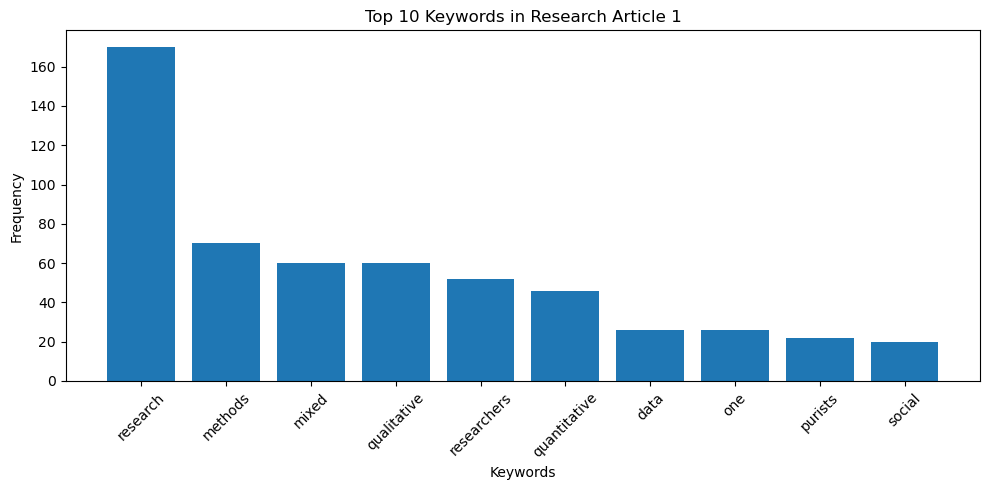


ORIGINAL WORD COUNT: 4490
SUMMARY WORD COUNT: 539


In [7]:

#3.3:

# Import required libraries
import matplotlib.pyplot as plt

from collections import Counter
from nltk.tokenize import sent_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer

# Download sentence tokenizer
nltk.download('punkt')
nltk.download('punkt_tab')

#Retrieve the first research article
article = df_articles.iloc[0]['Content']

print("FIRST RESEARCH ARTICLE:")
print(df_articles.iloc[0]['Article_Name'])

#Split article into sentences
sentences = sent_tokenize(article)

#Apply TF-IDF summarisation
if len(sentences) > 1:

    vectorizer = TfidfVectorizer(stop_words='english')

    tfidf_matrix = vectorizer.fit_transform(sentences)

    # Calculate sentence importance scores
    sentence_scores = tfidf_matrix.sum(axis=1).A1

    # Select the three highest-scoring sentences
    top_indices = sorted(
        sentence_scores.argsort()[-3:]
    )

    summary = ' '.join(
        sentences[i] for i in top_indices
    )

else:
    summary = article

#Display summary
print("\nEXTRACTED ARTICLE SUMMARY:")
print(summary)

# Step 4: Identify frequent keywords
words = re.findall(r'\b[a-zA-Z]{3,}\b', article.lower())

stop_words = set(nltk.corpus.stopwords.words('english'))

keywords = [
    word for word in words
    if word not in stop_words
]

word_counts = Counter(keywords)

top_words = word_counts.most_common(10)

#Display keyword frequencies
print("\nTOP 10 KEYWORDS:")
for word, count in top_words:
    print(word, ":", count)

#Visualise keyword frequencies
words_list, counts_list = zip(*top_words)

plt.figure(figsize=(10, 5))

plt.bar(words_list, counts_list)

plt.title('Top 10 Keywords in Research Article 1')
plt.xlabel('Keywords')
plt.ylabel('Frequency')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#Compare original and summarised content
print("\nORIGINAL WORD COUNT:", len(words))
print("SUMMARY WORD COUNT:", len(summary.split()))



In [ ]:
#3.4

REMAINING ARTICLES:
['research_2.txt', 'research_3.txt', 'research_4.txt', 'research_5.txt']

Total remaining articles: 4

TOP 10 KEYWORDS:
research : 229
study : 133
alpha : 117
data : 96
development : 92
one : 85
researcher : 84
design : 83
triangulation : 82
value : 67


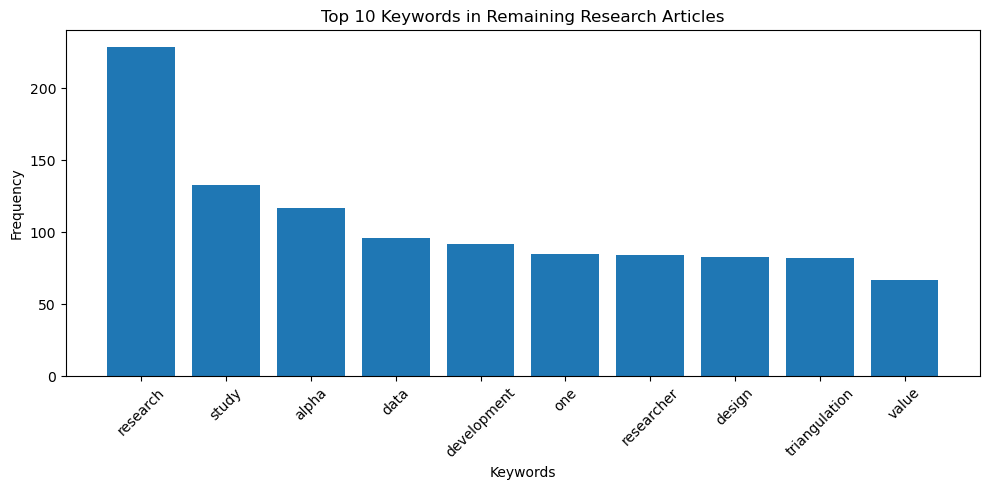


AGGREGATE SUMMARISATION RESULTS
Original word count: 8993
Summary word count: 8993
Content reduction: 0.0 %


In [11]:
import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity

#Select remaining articles
remaining_articles = df_articles.iloc[1:].copy()

#Combine all remaining article contents
combined_text = ' '.join(
    remaining_articles['Cleaned_Content'].dropna()
)

print("REMAINING ARTICLES:")
print(remaining_articles['Article_Name'].tolist())

print("\nTotal remaining articles:", len(remaining_articles))

#Split combined content into sentences
sentences = sent_tokenize(combined_text)

#Remove very short sentences
sentences = [
    sentence for sentence in sentences
    if len(sentence.split()) > 3
]

#Apply TextRank summarisation
vectorizer = TfidfVectorizer(
    stop_words='english'
)

tfidf_matrix = vectorizer.fit_transform(sentences)

#Calculate sentence similarity
similarity_matrix = cosine_similarity(tfidf_matrix)

#Build similarity graph
graph = nx.from_numpy_array(similarity_matrix)

#Apply PageRank to rank sentences
scores = nx.pagerank(graph, max_iter=100)

# Select the top 10 important sentences
ranked_sentences = sorted(
    scores.items(),
    key=lambda x: x[1],
    reverse=True
)

top_indices = sorted(
    [index for index, score in ranked_sentences[:10]]
)

#Generate aggregate summary
summary = ' '.join(
    sentences[index] for index in top_indices
)


#Extract frequent keywords
words = re.findall(r'\b[a-zA-Z]{3,}\b', combined_text.lower())

stop_words = set(stopwords.words('english'))

keywords = [
    word for word in words
    if word not in stop_words
]

word_counts = Counter(keywords)

top_words = word_counts.most_common(10)

print("\nTOP 10 KEYWORDS:")
for word, count in top_words:
    print(word, ":", count)

#Visualise keyword frequency
words_list, counts_list = zip(*top_words)

plt.figure(figsize=(10, 5))
plt.bar(words_list, counts_list)

plt.title('Top 10 Keywords in Remaining Research Articles')
plt.xlabel('Keywords')
plt.ylabel('Frequency')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#Compare original and summary word counts
original_count = len(combined_text.split())
summary_count = len(summary.split())

print("\nAGGREGATE SUMMARISATION RESULTS")
print("Original word count:", original_count)
print("Summary word count:", summary_count)

reduction = (
    (original_count - summary_count) / original_count
) * 100 if original_count else 0

print("Content reduction:", round(reduction, 2), "%")



TOPICS AND THEIR MOST IMPORTANT WORDS

Topic 1:
data, triangulation, researcher, research, study, method, qualitative, design, reflexivity, denzin

Topic 2:
research, method, development, researcher, qualitative, mixed, design, process, quantitative, developmental

Topic 3:
alpha, cronbach, instrument, value, reliability, science, scale, study, item, education

TOPIC DISTRIBUTION PER ARTICLE
     Article_Name  Topic 1  Topic 2  Topic 3
0  research_1.txt    0.000      1.0      0.0
1  research_2.txt    0.999      0.0      0.0
2  research_3.txt    0.000      1.0      0.0
3  research_4.txt    0.000      0.0      1.0
4  research_5.txt    1.000      0.0      0.0

OVERALL TOPIC DISTRIBUTION
Topic 1: 39.98%
Topic 2: 40.00%
Topic 3: 20.01%


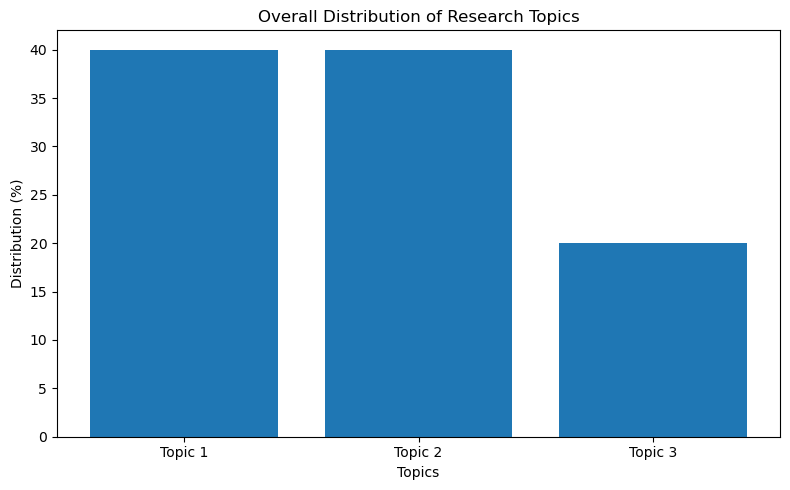

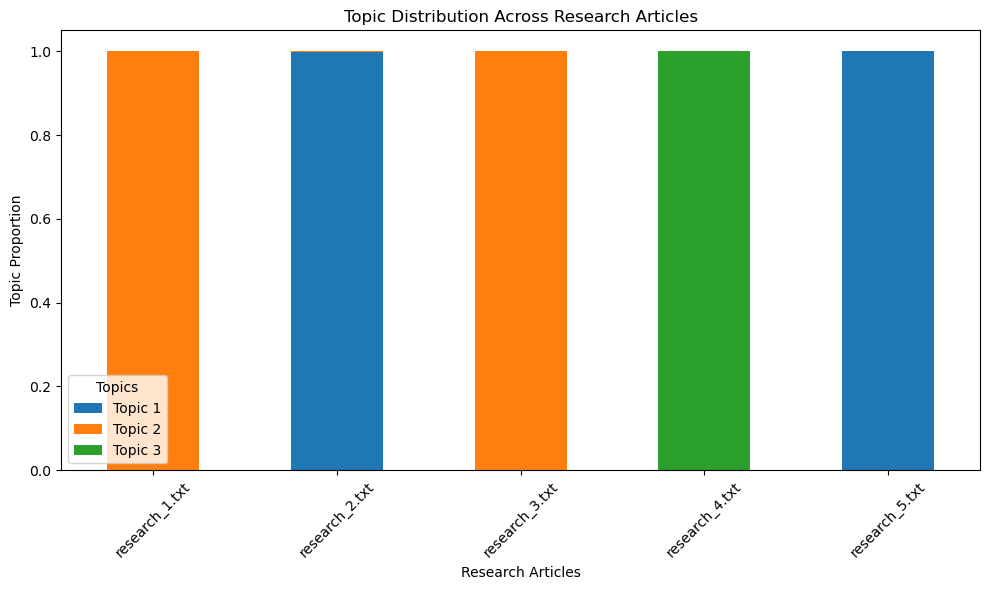

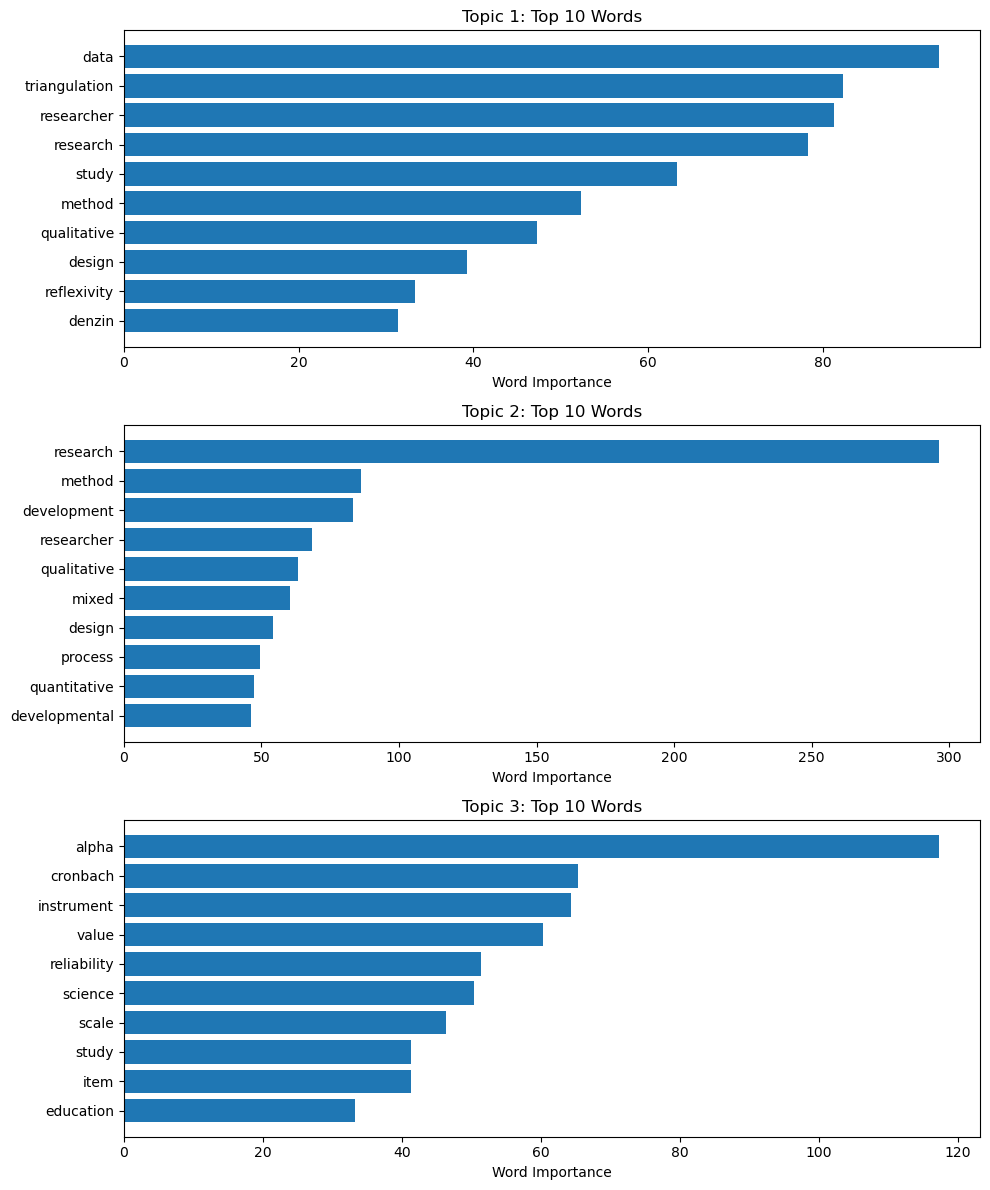

In [13]:
#Question 4
#4.1
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

#Select cleaned research articles
documents = df_articles['Cleaned_Content'].fillna('')

#Convert text into document-term matrix
vectorizer = CountVectorizer(
    max_features=1000,
    stop_words='english',
    min_df=1
)

dtm = vectorizer.fit_transform(documents)

#Define the number of topics
n_topics = 3

# Step 4: Apply LDA topic modelling
lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    max_iter=20,
    learning_method='batch'
)

lda_model.fit(dtm)

#Display top words for each topic
feature_names = vectorizer.get_feature_names_out()

print("TOPICS AND THEIR MOST IMPORTANT WORDS")

for topic_index, topic in enumerate(lda_model.components_):

    top_indices = topic.argsort()[-10:][::-1]

    top_words = [
        feature_names[i] for i in top_indices
    ]

    print(f"\nTopic {topic_index + 1}:")
    print(", ".join(top_words))

#Calculate topic distribution per article
topic_distribution = lda_model.transform(dtm)

topic_columns = [
    f'Topic {i + 1}' for i in range(n_topics)
]

distribution_df = pd.DataFrame(
    topic_distribution,
    columns=topic_columns
)

distribution_df.insert(
    0, 'Article_Name', df_articles['Article_Name'].values
)

print("\nTOPIC DISTRIBUTION PER ARTICLE")
print(distribution_df.round(3))

#Calculate overall topic distribution
average_distribution = topic_distribution.mean(axis=0)

print("\nOVERALL TOPIC DISTRIBUTION")

for i, value in enumerate(average_distribution):
    print(f"Topic {i + 1}: {value * 100:.2f}%")

#Visualise overall topic distribution
plt.figure(figsize=(8, 5))

plt.bar(
    topic_columns,
    average_distribution * 100
)

plt.title('Overall Distribution of Research Topics')
plt.xlabel('Topics')
plt.ylabel('Distribution (%)')

plt.tight_layout()
plt.show()

#Visualise topic distribution across articles
distribution_df.set_index(
    'Article_Name'
)[topic_columns].plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Topic Distribution Across Research Articles')
plt.xlabel('Research Articles')
plt.ylabel('Topic Proportion')

plt.xticks(rotation=45)
plt.legend(title='Topics')
plt.tight_layout()
plt.show()

#Visualise top words in each topic
fig, axes = plt.subplots(
    n_topics, 1,
    figsize=(10, 12)
)

for i, topic in enumerate(lda_model.components_):

    top_indices = topic.argsort()[-10:][::-1]

    words = feature_names[top_indices]
    weights = topic[top_indices]

    axes[i].barh(words[::-1], weights[::-1])
    axes[i].set_title(f'Topic {i + 1}: Top 10 Words')
    axes[i].set_xlabel('Word Importance')

plt.tight_layout()
plt.show()

# Step 11: Save topic distributions
distribution_df.to_csv(
    'lda_topic_distribution.csv',
    index=False
)



In [14]:
#4.2
!pip install pyLDAvis

   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.6 MB ? eta -:--:--
   ------------ --------------------------- 0.8/2.6 MB 2.0 MB/s eta 0:00:01
   ---------------- ----------------------- 1.0/2.6 MB 1.5 MB/s eta 0:00:02
   -------------------- ------------------- 1.3/2.6 MB 1.7 MB/s eta 0:00:01
   ------------------------ --------------- 1.6/2.6 MB 1.5 MB/s eta 0:00:01
   ------------------------ --------------- 1.6/2.6 MB 1.5 MB/s eta 0:00:01
   -------------------------------- ------- 2.1/2.6 MB 1.4 MB/s eta 0:00:01
   ------------------------------------ --- 2.4/2.6 MB 1.3 MB/s eta 0:00:01
   ------------------------------------ --- 2.4/2.6 MB 1.3 MB/s eta 0:00:01
   ---------------------------------------- 2.6/2.6 MB 1.3 MB/s  0:00:02
   ----------------------------------------

In [15]:
import pyLDAvis
import pyLDAvis.lda_model
import pandas as pd
import matplotlib.pyplot as plt

#Prepare LDA visualisation
vis = pyLDAvis.lda_model.prepare(
    lda_model,
    dtm,
    vectorizer,
    sort_topics=False
)

#Display interactive Intertopic Distance Map
pyLDAvis.display(vis)

#Save interactive visualisation as HTML
pyLDAvis.save_html(
    vis,
    'research_topic_distance_map.html'
)

print("Interactive LDA visualisation saved successfully.")

#Display most important words per topic
feature_names = vectorizer.get_feature_names_out()

print("\nMOST IMPORTANT WORDS PER TOPIC")

for topic_index, topic in enumerate(lda_model.components_):

    top_indices = topic.argsort()[-10:][::-1]

    top_words = [
        feature_names[i] for i in top_indices
    ]

    print(f"\nTopic {topic_index + 1}:")
    print(", ".join(top_words))

#Display overall topic proportions
topic_distribution = lda_model.transform(dtm)

average_distribution = topic_distribution.mean(axis=0)

print("\nOVERALL TOPIC DISTRIBUTION")

for i, value in enumerate(average_distribution):
    print(f"Topic {i + 1}: {value * 100:.2f}%")

print("\nLDA INTERACTIVE VISUALISATION COMPLETED.")


Interactive LDA visualisation saved successfully.

MOST IMPORTANT WORDS PER TOPIC

Topic 1:
data, triangulation, researcher, research, study, method, qualitative, design, reflexivity, denzin

Topic 2:
research, method, development, researcher, qualitative, mixed, design, process, quantitative, developmental

Topic 3:
alpha, cronbach, instrument, value, reliability, science, scale, study, item, education

OVERALL TOPIC DISTRIBUTION
Topic 1: 39.98%
Topic 2: 40.00%
Topic 3: 20.01%

LDA INTERACTIVE VISUALISATION COMPLETED.
